This is a four-channel, 500 Hz ECG recording captured during a single jump. We compare band-pass filtering, wavelet denoising, and their combination. There is no clean reference signal, so choose the result with a stable baseline and realistic P-QRS-T shapes—not merely the smoothest result.


In [84]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import wfdb
import pywt
from scipy import signal
plt.style.use('default')

DATA_FOLDER = Path(r"C:\Users\jhala\OneDrive\Desktop\Internship\Datasets\ECG_DATASETS")
RECORD_ID = "test26_45j"
CHANNEL = 3        
DISPLAY_SECONDS = 15


test26_45j: 500 Hz, 4 channels, using ECG 4
Duration: 8.00 seconds


<Figure size 2500x500 with 0 Axes>

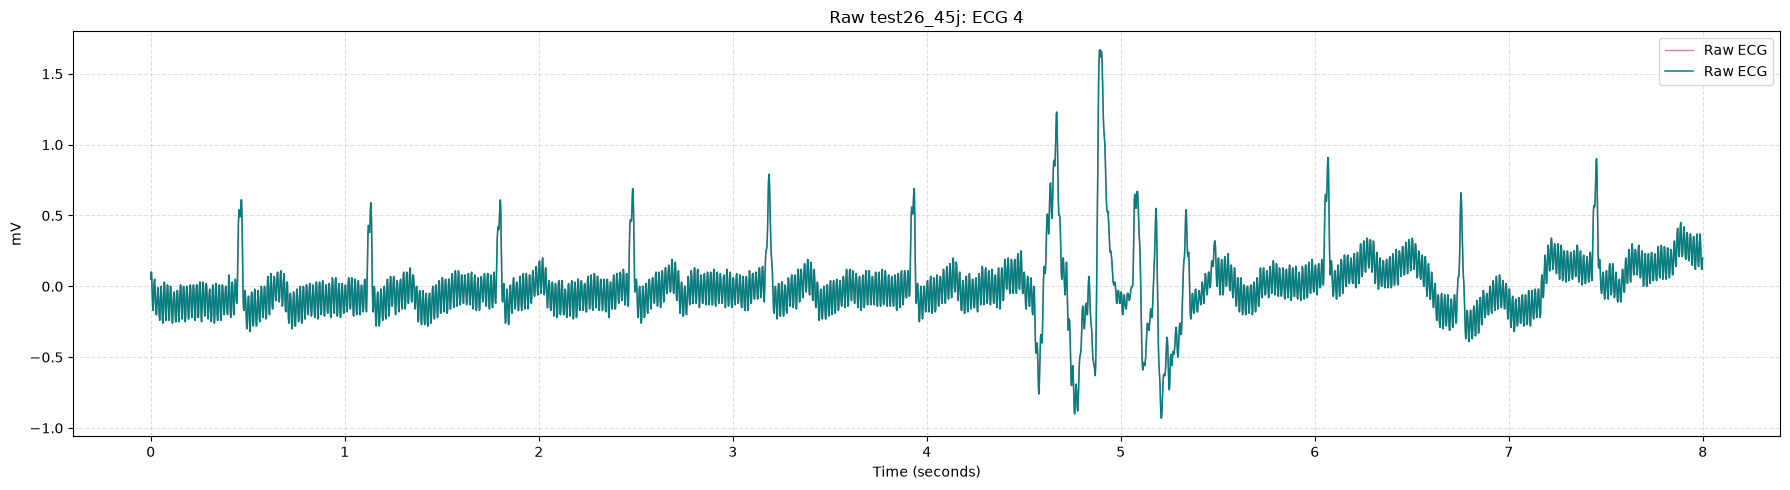

In [85]:
record_path = DATA_FOLDER / RECORD_ID
if not record_path.with_suffix(".hea").exists():
    raise FileNotFoundError(f"Cannot find {record_path.with_suffix('.hea')}. Update DATA_FOLDER.")

record = wfdb.rdrecord(str(record_path))
fs = float(record.fs)

if not 0 <= CHANNEL < record.n_sig:
    raise IndexError(f"CHANNEL must be 0 to {record.n_sig - 1}")

raw = np.asarray(record.p_signal[:, CHANNEL], dtype=float)
raw = np.nan_to_num(raw, nan=np.nanmedian(raw))
unit = record.units[CHANNEL] or "amplitude"
channel_name = record.sig_name[CHANNEL]

print(f"{RECORD_ID}: {fs:g} Hz, {record.n_sig} channels, using {channel_name}")
print(f"Duration: {len(raw)/fs:.2f} seconds")

def plot_pair(raw_signal, cleaned_signal, title, label):
    n = min(len(raw_signal), int(DISPLAY_SECONDS * fs))
    t = np.arange(n) / fs
    plt.figure(figsize=(18, 5))
    plt.plot(t, raw_signal[:n], color="crimson", alpha=.55, lw=1, label="Raw ECG")
    plt.plot(t, cleaned_signal[:n], color="teal", lw=1.1, label=label)
    plt.title(title); plt.xlabel("Time (seconds)"); plt.ylabel(unit)
    plt.grid(True, linestyle="--", alpha=.4); plt.legend(); plt.tight_layout(); plt.show()
plt.figure(figsize=(25, 5))
plot_pair(raw, raw, f"Raw {RECORD_ID}: {channel_name}", "Raw ECG")


## 0.5–40 Hz band-pass filtering

The lower edge reduces slow movement/baseline drift; the upper edge reduces fast noise. `sosfiltfilt` filters forward and backward, preventing a time shift in the heartbeats.


<Figure size 2500x500 with 0 Axes>

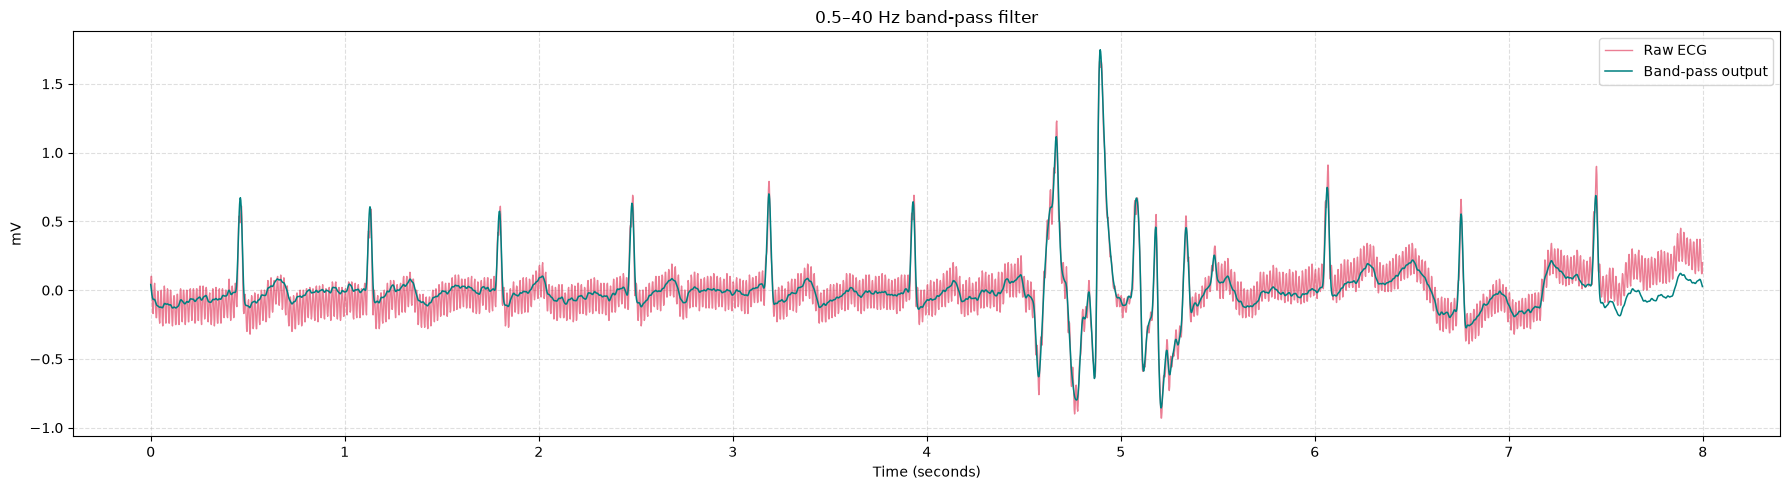

In [ ]:
# def bandpass_ecg(x, fs, low_hz=0.5, high_hz=40.0):
#     sos = signal.butter(4, [low_hz, high_hz], btype="bandpass", fs=fs, output="sos")
#     return signal.sosfiltfilt(sos, x)

# bandpass = bandpass_ecg(raw, fs)
# plt.figure(figsize=(25, 5))
# plot_pair(raw, bandpass, "0.5–40 Hz band-pass filter", "Band-pass output")


## Notch Filter


<Figure size 2500x500 with 0 Axes>

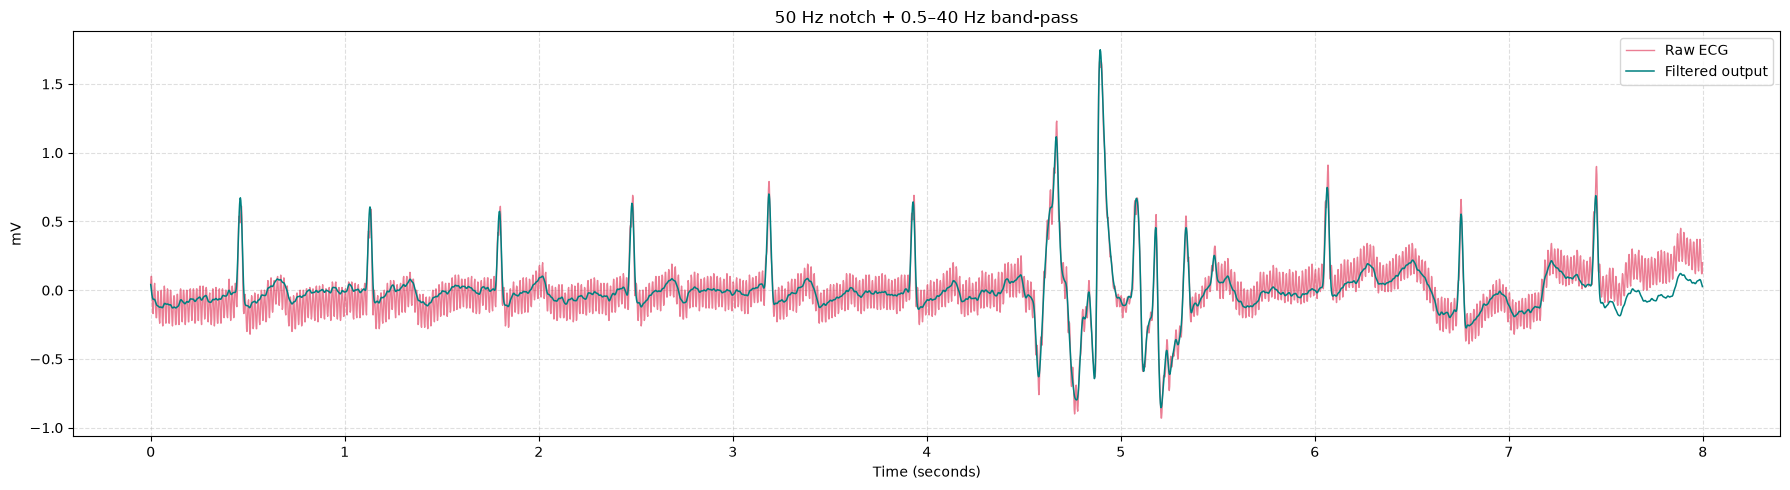

In [118]:
def bandpass_ecg(x, fs, low_hz=0.5, high_hz=40.0, notch_hz=50.0, notch_q=30.0):
    
    # Remove mains interference
    b_notch, a_notch = signal.iirnotch(notch_hz, notch_q, fs=fs)
    x_notched = signal.filtfilt(b_notch, a_notch, x)

    # Retain ECG frequency band
    sos = signal.butter(
        4, [low_hz, high_hz],
        btype="bandpass", fs=fs, output="sos"
    )
    return signal.sosfiltfilt(sos, x_notched)

bandpass = bandpass_ecg(raw, fs)

plt.figure(figsize=(25, 5))
# plt.ylim(-2, 2)
# plt.xlim(4,6)
plot_pair(raw, bandpass, "50 Hz notch + 0.5–40 Hz band-pass", "Filtered output")

## Wavelet denoising

Wavelets split the ECG into fast and slow parts. The code softens small, noise-like fast components and removes the slowest baseline component. It can preserve sharp QRS peaks better than an aggressive low-pass filter.


<Figure size 2500x500 with 0 Axes>

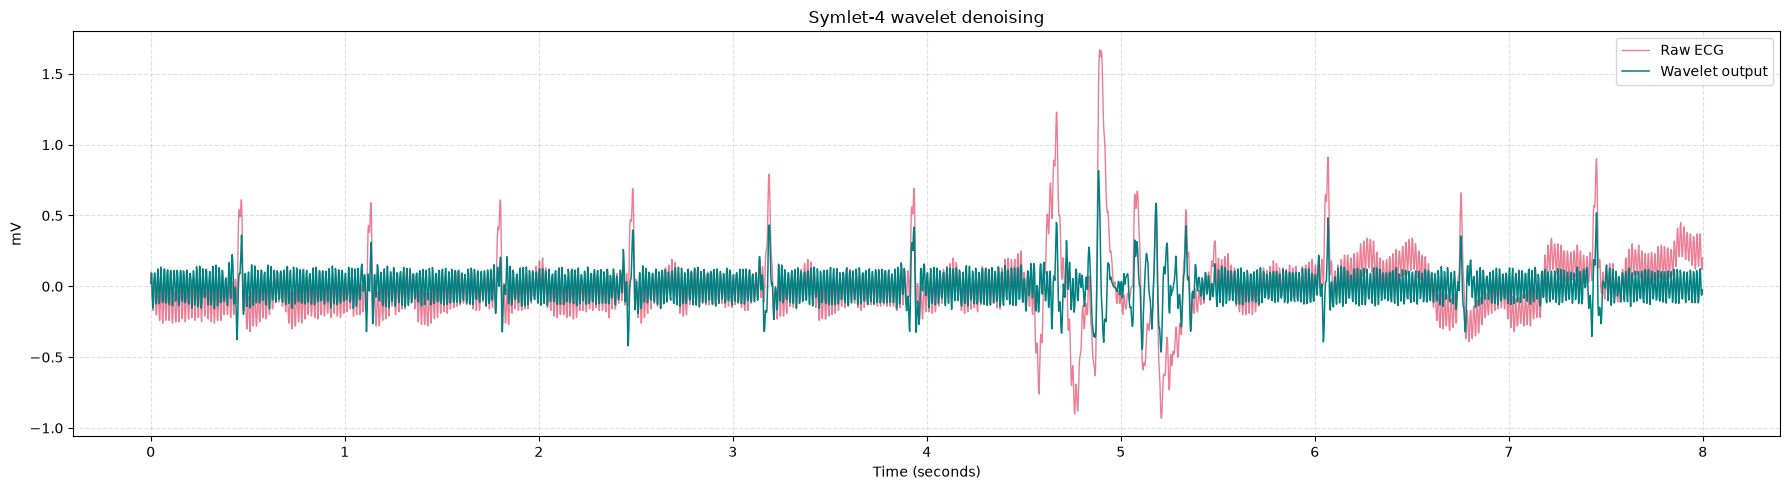

In [114]:
def wavelet_denoise(x, wavelet="sym4", level=4):
    """Data-driven wavelet thresholding for motion-contaminated ECG."""
    max_level = pywt.dwt_max_level(len(x), pywt.Wavelet(wavelet).dec_len) # calculate maximum decomposition level
    coeffs = pywt.wavedec(x, wavelet, level=min(level, max_level))
    coeffs[0] = np.zeros_like(coeffs[0])       # remove slow baseline component
    sigma = np.median(np.abs(coeffs[-1])) / .6745
    threshold = sigma * np.sqrt(2 * np.log(len(x)))
    coeffs[1:] = [pywt.threshold(c, threshold, mode="hard") for c in coeffs[1:]] # remove high-frequency noise
    return pywt.waverec(coeffs, wavelet)[:len(x)]

wavelet = wavelet_denoise(raw)
plt.figure(figsize=(25, 5))
plot_pair(raw, wavelet, "Symlet-4 wavelet denoising", "Wavelet output")


## Exp


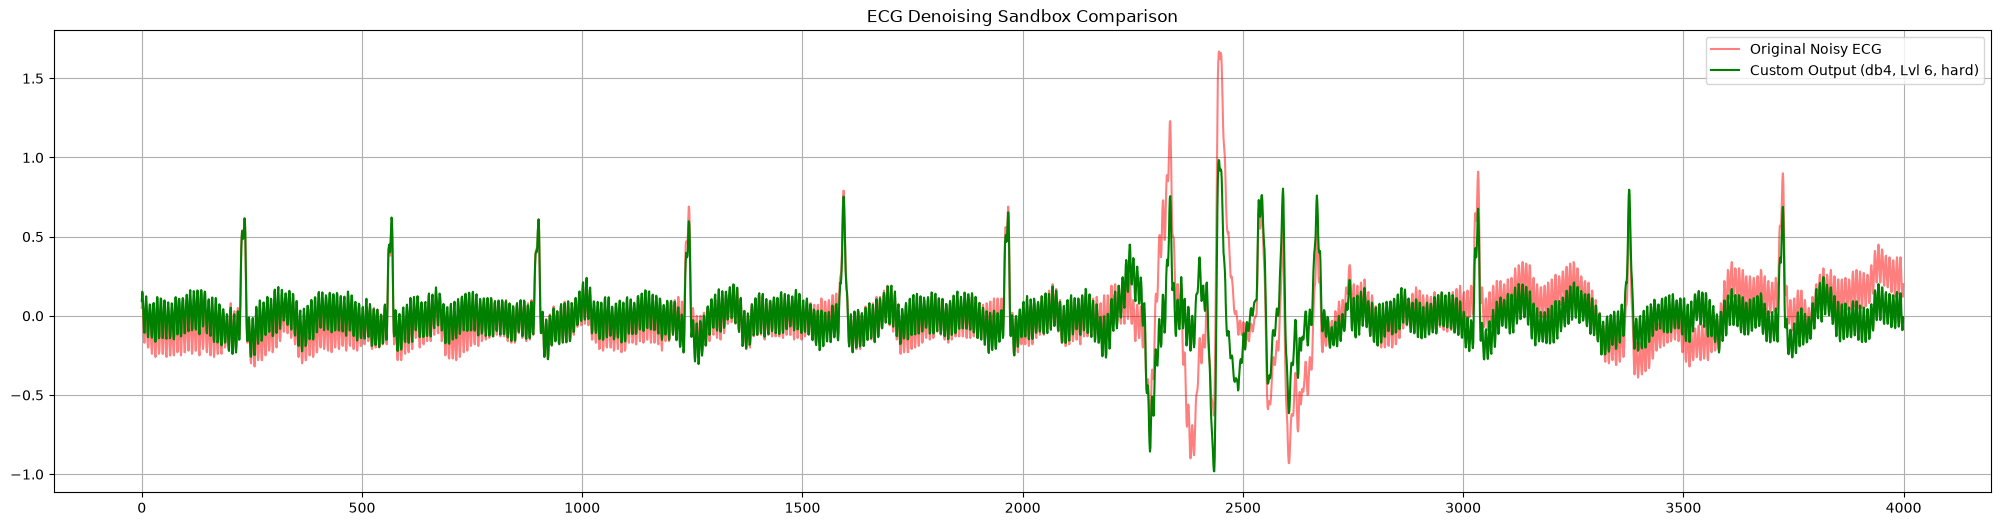

In [89]:
import numpy as np
import pywt
import matplotlib.pyplot as plt

# --- 1. Experimental Denoising Function ---
def experimental_wavelet_denoise(x, wavelet="sym4", level=4, threshold_multiplier=1.0, mode="soft", keep_baseline=False):
    """
    An enhanced version of your function built for playing with parameters.
    
    Parameters:
    - threshold_multiplier: 1.0 is standard. Increase (e.g., 2.0) for more filtering, decrease for less.
    - mode: "soft" (smooths peaks) or "hard" (keeps peak heights but leaves artifacts).
    - keep_baseline: Set to True to skip flattening the slow drift.
    """
    max_level = pywt.dwt_max_level(len(x), pywt.Wavelet(wavelet).dec_len)
    actual_level = min(level, max_level)
    
    # Decompose
    coeffs = pywt.wavedec(x, wavelet, level=actual_level)
    
    # Experiment 1: Toggle baseline wander removal
    if not keep_baseline:
        coeffs[0] = np.zeros_like(coeffs[0])
        
    # Estimate noise
    sigma = np.median(np.abs(coeffs[-1])) / .6745 # sigma estimates the noise level in the detail coefficients
    # coeffs[-1] is the detail coefficients at the highest level, which captures the finest details (often noise).
    # np.median(np.abs(coeffs[-1])) gives a robust estimate of the noise magnitude, and dividing by 0.6745 converts it to an estimate of the standard deviation (sigma) of the noise.
    # 0.6745 is a constant that relates the median absolute deviation (MAD) to the standard deviation for a normal distribution.
    
    # Experiment 2: Modify the threshold scaling
    base_threshold = sigma * np.sqrt(2 * np.log(len(x)))
    custom_threshold = base_threshold * threshold_multiplier
    # sigma is estimated noise strength.
    # len(x) is number of samples in the signal. 
    # The term sqrt(2 * log(len(x))) is derived from statistical theory and is used to set a threshold that adapts to the length of the signal. It helps ensure that the threshold is appropriately scaled for signals of different lengths.
    
    # Experiment 3: Swap between 'soft' and 'hard' thresholding
    coeffs[1:] = [pywt.threshold(c, custom_threshold, mode=mode) for c in coeffs[1:]]
    
    return pywt.waverec(coeffs, wavelet)[:len(x)]

# --- 2. Sandbox: Change these values to play! ---
# Load your 'raw' array here first
chosen_wavelet = "db4"           # Try: "sym4", "sym8", "db2", "haar", "coif2"
chosen_level = 6                 # Try: 1, 2, 4, 7 (Higher = flatter baseline)
multiplier = 0.5                 # Try: 0.2 (under-filter) or 3.0 (over-filter)
thresh_mode = "hard"             # Try: "soft" or "hard"
save_baseline = False            # Try: True (keeps the slow rolling wave)

# Run the experimental version
clean_signal = experimental_wavelet_denoise(
    raw, 
    wavelet=chosen_wavelet, 
    level=chosen_level, 
    threshold_multiplier=multiplier, 
    mode=thresh_mode, 
    keep_baseline=save_baseline
)

# Plotting the results
plt.figure(figsize=(25, 6))
plt.plot(raw, label="Original Noisy ECG", alpha=0.5, color="red")
plt.plot(clean_signal, label=f"Custom Output ({chosen_wavelet}, Lvl {chosen_level}, {thresh_mode})", color="green", linewidth=1.5)
plt.title("ECG Denoising Sandbox Comparison")
plt.legend()
plt.grid(True)
plt.show()


# Wavelet Denoising Exp

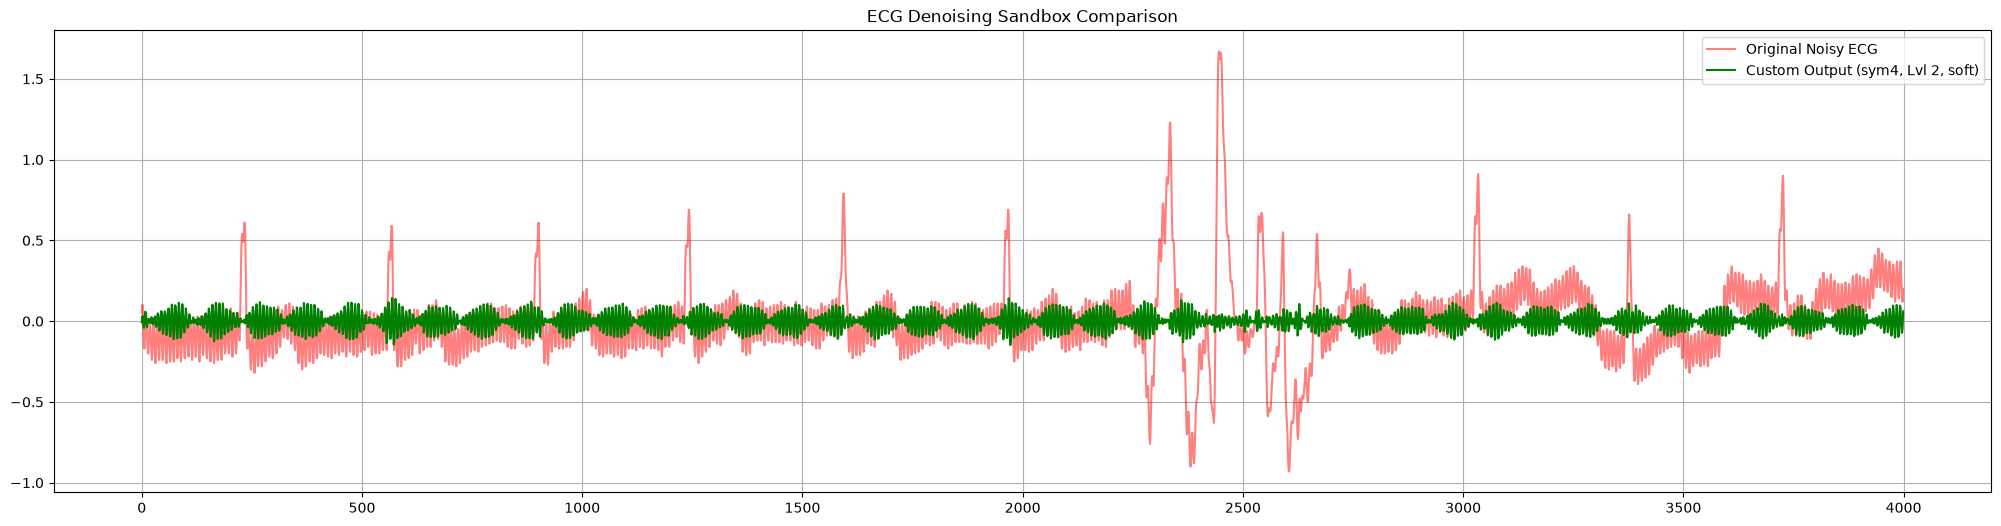

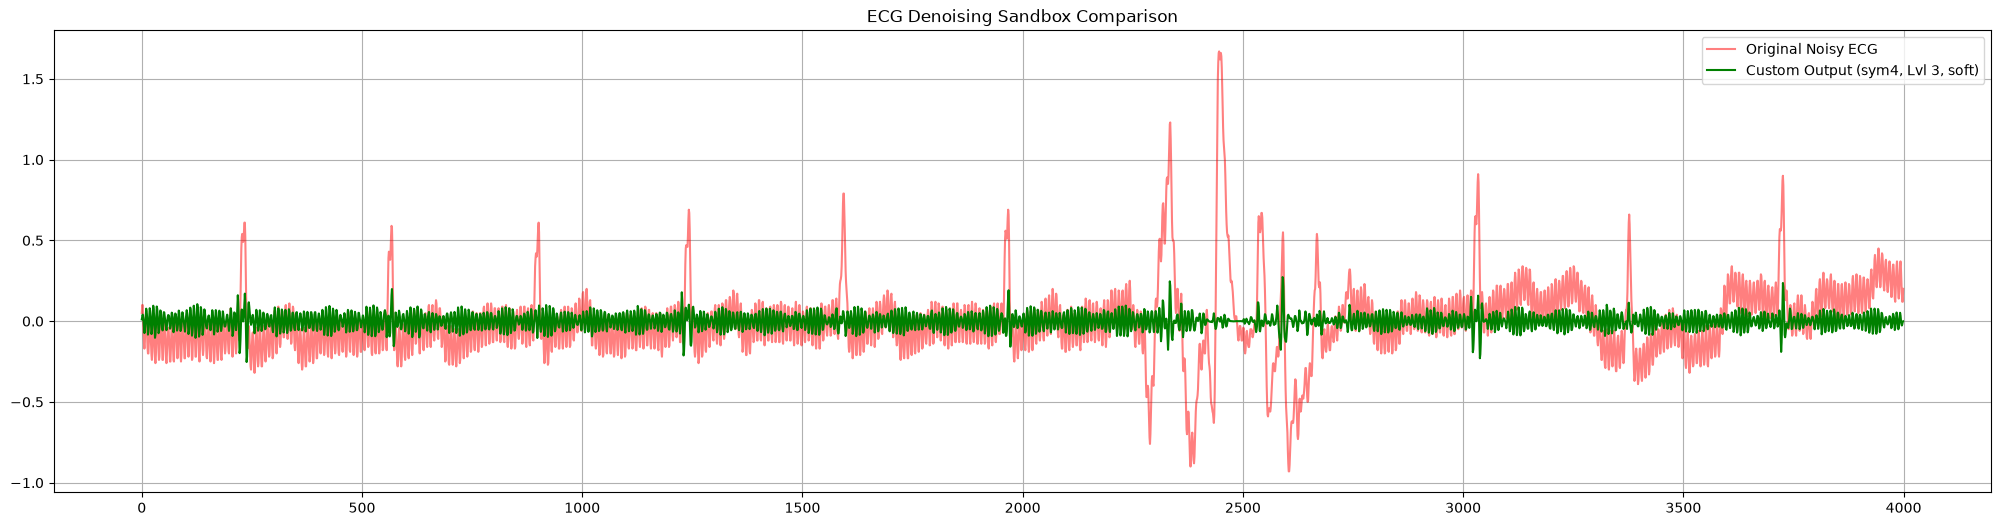

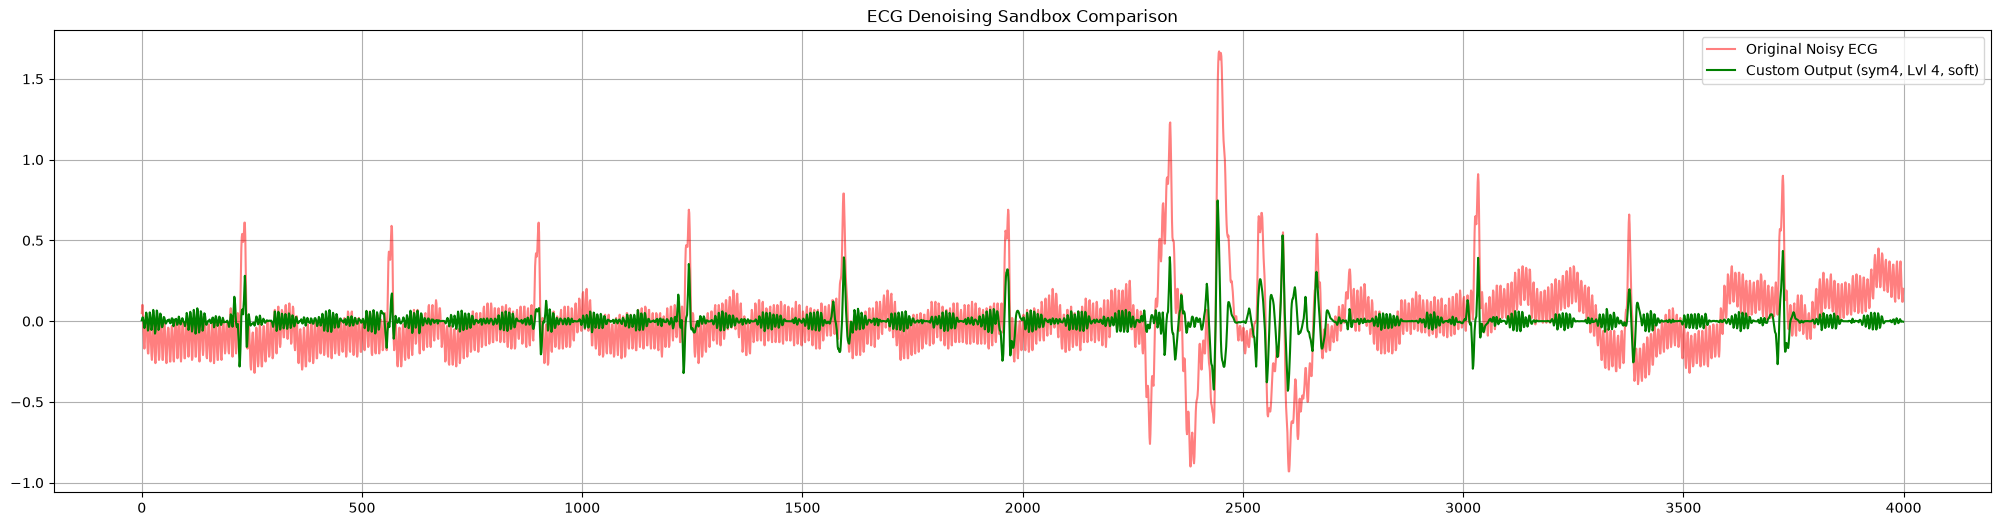

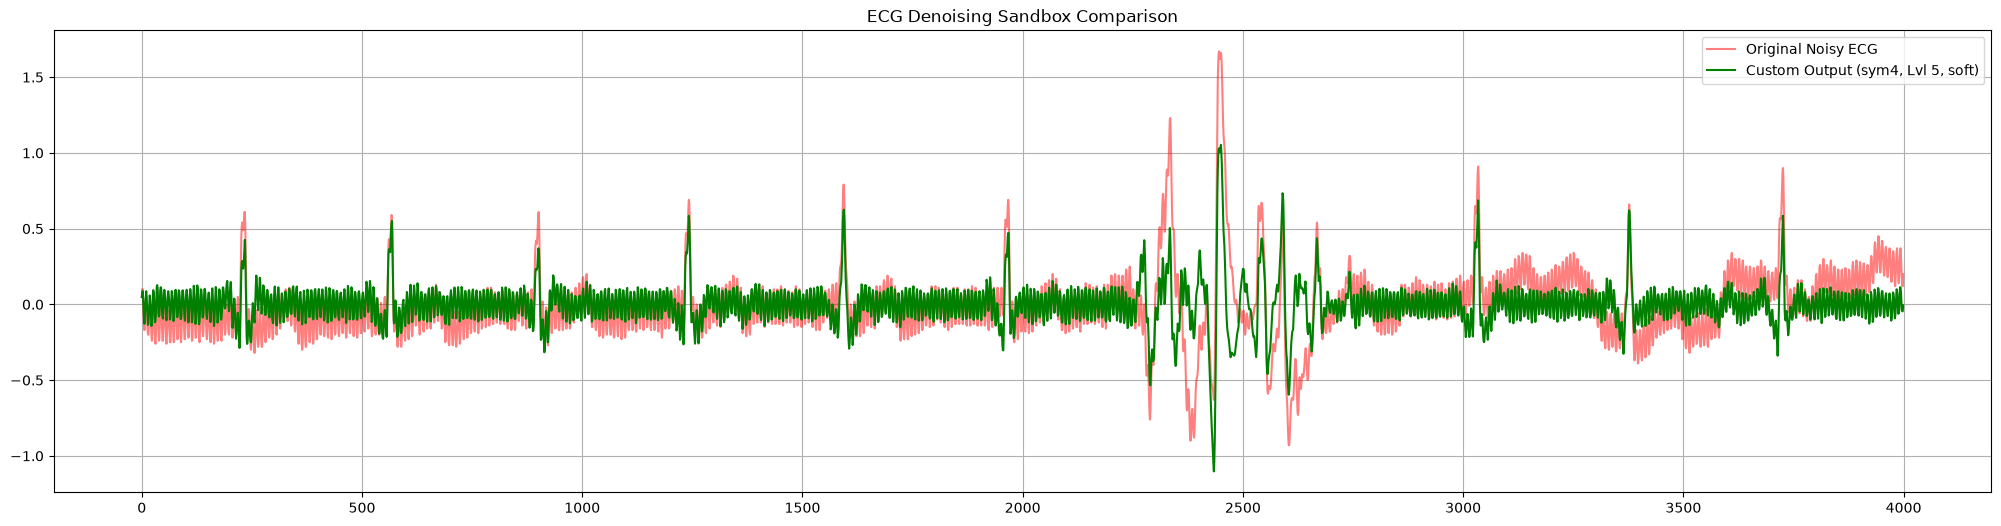

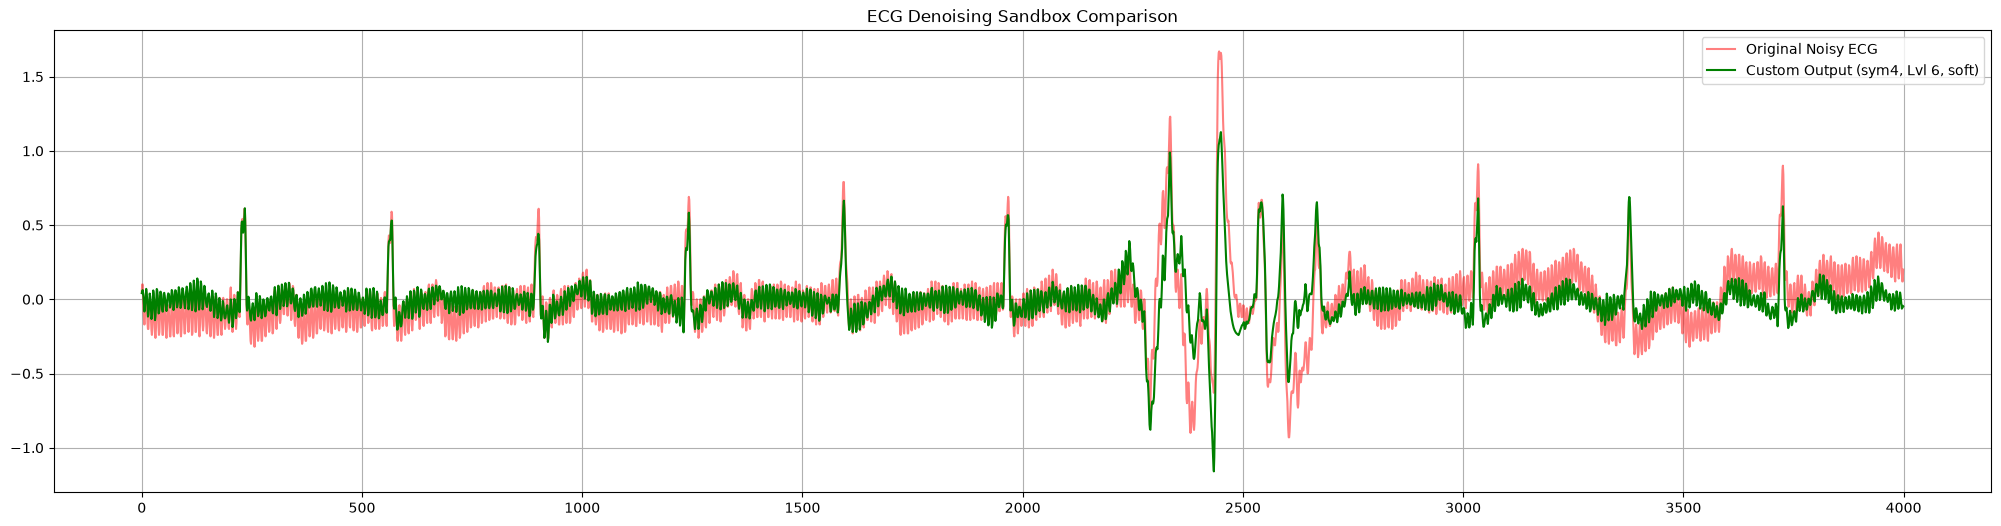

In [139]:
import numpy as np
import pywt
import matplotlib.pyplot as plt

# --- 1. Experimental Denoising Function ---
def experimental_wavelet_denoise(x, wavelet="sym4", level=3, threshold_multiplier=0.1, mode="soft", keep_baseline=False):
    
    max_level = pywt.dwt_max_level(len(x), pywt.Wavelet(wavelet).dec_len)
    actual_level = min(level, max_level)
    
    # Decompose
    coeffs = pywt.wavedec(x, wavelet, level=actual_level)
    
    # Experiment 1: Toggle baseline wander removal
    if not keep_baseline:
        coeffs[0] = np.zeros_like(coeffs[0])
        
    # Estimate noise
    sigma = np.median(np.abs(coeffs[2])) / 5.0 # sigma estimates the noise level in the detail coefficients
    # coeffs[-1] is the detail coefficients at the highest level, which captures the finest details (often noise).
    # np.median(np.abs(coeffs[-1])) gives a robust estimate of the noise magnitude, and dividing by 0.6745 converts it to an estimate of the standard deviation (sigma) of the noise.
    # 0.6745 is a constant that relates the median absolute deviation (MAD) to the standard deviation for a normal distribution.
    
    # Experiment 2: Modify the threshold scaling
    base_threshold = sigma * np.sqrt(2 * np.log(len(x)))
    custom_threshold = base_threshold * threshold_multiplier
    # sigma is estimated noise strength.
    # len(x) is number of samples in the signal. 
    # The term sqrt(2 * log(len(x))) is derived from statistical theory and is used to set a threshold that adapts to the length of the signal. It helps ensure that the threshold is appropriately scaled for signals of different lengths.
    
    # Experiment 3: Swap between 'soft' and 'hard' thresholding
    coeffs[1:] = [pywt.threshold(c, custom_threshold, mode=mode) for c in coeffs[1:]]
    
    return pywt.waverec(coeffs, wavelet)[:len(x)]

# --- 2. Sandbox: Change these values to play! ---
# Load your 'raw' array here first
chosen_wavelet1 = "sym4"           # Try: "sym4", "sym8", "db2", "haar", "coif2"
chosen_level1 = 2             # Try: 1, 2, 4, 7 (Higher = flatter baseline)
multiplier1 = 1.0                 # Try: 0.2 (under-filter) or 3.0 (over-filter)
thresh_mode1 = "soft"             # Try: "soft" or "hard"
save_baseline1 = False            # Try: True (keeps the slow rolling wave)

# Run the experimental version
clean_signal = experimental_wavelet_denoise(
    raw, 
    wavelet=chosen_wavelet, 
    level=chosen_level1, 
    threshold_multiplier=multiplier1, 
    mode=thresh_mode1, 
    keep_baseline=save_baseline1
)

# Plotting the results
plt.figure(figsize=(25, 6))
plt.plot(raw, label="Original Noisy ECG", alpha=0.5, color="red")
plt.plot(clean_signal, label=f"Custom Output ({chosen_wavelet1}, Lvl {chosen_level1}, {thresh_mode1})", color="green", linewidth=1.5)
plt.title("ECG Denoising Sandbox Comparison")
# # plt.ylim(-0.1, 0.1) 
# plt.xlim(1500,2000)
plt.legend()
plt.grid(True)
plt.show()









chosen_wavelet2 = "sym4"           # Try: "sym4", "sym8", "db2", "haar", "coif2"
chosen_level2 = 3             # Try: 1, 2, 4, 7 (Higher = flatter baseline)
multiplier2 = 1.0                 # Try: 0.2 (under-filter) or 3.0 (over-filter)
thresh_mode2 = "soft"             # Try: "soft" or "hard"
save_baseline2 = False 

clean_signal = experimental_wavelet_denoise(
    raw, 
    wavelet=chosen_wavelet2, 
    level=chosen_level2, 
    threshold_multiplier=multiplier2, 
    mode=thresh_mode2, 
    keep_baseline=save_baseline2
)

# Plotting the results
plt.figure(figsize=(25, 6))
plt.plot(raw, label="Original Noisy ECG", alpha=0.5, color="red")
plt.plot(clean_signal, label=f"Custom Output ({chosen_wavelet2}, Lvl {chosen_level2}, {thresh_mode2})", color="green", linewidth=1.5)
plt.title("ECG Denoising Sandbox Comparison")
# # plt.ylim(-0.1, 0.1) 
# plt.xlim(1500,2000)
plt.legend()
plt.grid(True)
plt.show()











chosen_wavelet3 = "sym4"           # Try: "sym4", "sym8", "db2", "haar", "coif2"
chosen_level3 = 4             # Try: 1, 2, 4, 7 (Higher = flatter baseline)
multiplier3 = 1.0                 # Try: 0.2 (under-filter) or 3.0 (over-filter)
thresh_mode3 = "soft"             # Try: "soft" or "hard"
save_baseline3 = False 

clean_signal = experimental_wavelet_denoise(
    raw, 
    wavelet=chosen_wavelet3, 
    level=chosen_level3, 
    threshold_multiplier=multiplier3, 
    mode=thresh_mode3, 
    keep_baseline=save_baseline3
)

# Plotting the results
plt.figure(figsize=(25, 6))
plt.plot(raw, label="Original Noisy ECG", alpha=0.5, color="red")
plt.plot(clean_signal, label=f"Custom Output ({chosen_wavelet3}, Lvl {chosen_level3}, {thresh_mode3})", color="green", linewidth=1.5)
plt.title("ECG Denoising Sandbox Comparison")
# # plt.ylim(-0.1, 0.1) 
# plt.xlim(1500,2000)
plt.legend()
plt.grid(True)
plt.show()













chosen_wavelet4 = "sym4"           # Try: "sym4", "sym8", "db2", "haar", "coif2"
chosen_level4 = 5             # Try: 1, 2, 4, 7 (Higher = flatter baseline)
multiplier4 = 1.0                 # Try: 0.2 (under-filter) or 3.0 (over-filter)
thresh_mode4 = "soft"             # Try: "soft" or "hard"
save_baseline4 = False 

clean_signal = experimental_wavelet_denoise(
    raw, 
    wavelet=chosen_wavelet4, 
    level=chosen_level4, 
    threshold_multiplier=multiplier4, 
    mode=thresh_mode4, 
    keep_baseline=save_baseline4
)

# Plotting the results
plt.figure(figsize=(25, 6))
plt.plot(raw, label="Original Noisy ECG", alpha=0.5, color="red")
plt.plot(clean_signal, label=f"Custom Output ({chosen_wavelet4}, Lvl {chosen_level4}, {thresh_mode4})", color="green", linewidth=1.5)
plt.title("ECG Denoising Sandbox Comparison")
# # plt.ylim(-0.1, 0.1) 
# plt.xlim(1500,2000)
plt.legend()
plt.grid(True)
plt.show()














chosen_wavelet5 = "sym4"           # Try: "sym4", "sym8", "db2", "haar", "coif2"
chosen_level5 = 6             # Try: 1, 2, 4, 7 (Higher = flatter baseline)
multiplier5 = 1.0                 # Try: 0.2 (under-filter) or 3.0 (over-filter)
thresh_mode5 = "soft"             # Try: "soft" or "hard"
save_baseline5 = False 

clean_signal = experimental_wavelet_denoise(
    raw, 
    wavelet=chosen_wavelet5, 
    level=chosen_level5, 
    threshold_multiplier=multiplier5, 
    mode=thresh_mode5, 
    keep_baseline=save_baseline5
)

# Plotting the results
plt.figure(figsize=(25, 6))
plt.plot(raw, label="Original Noisy ECG", alpha=0.5, color="red")
plt.plot(clean_signal, label=f"Custom Output ({chosen_wavelet5}, Lvl {chosen_level5}, {thresh_mode5})", color="green", linewidth=1.5)
plt.title("ECG Denoising Sandbox Comparison")
# # plt.ylim(-0.1, 0.1) 
# plt.xlim(1500,2000)
plt.legend()
plt.grid(True)
plt.show()

## band-pass + wavelet

This is the best starting candidate for the jump recording: first remove broad frequency-range artifact, then remove remaining irregular fluctuations. If it visibly rounds or removes QRS peaks, choose Method A instead.


<Figure size 2500x500 with 0 Axes>

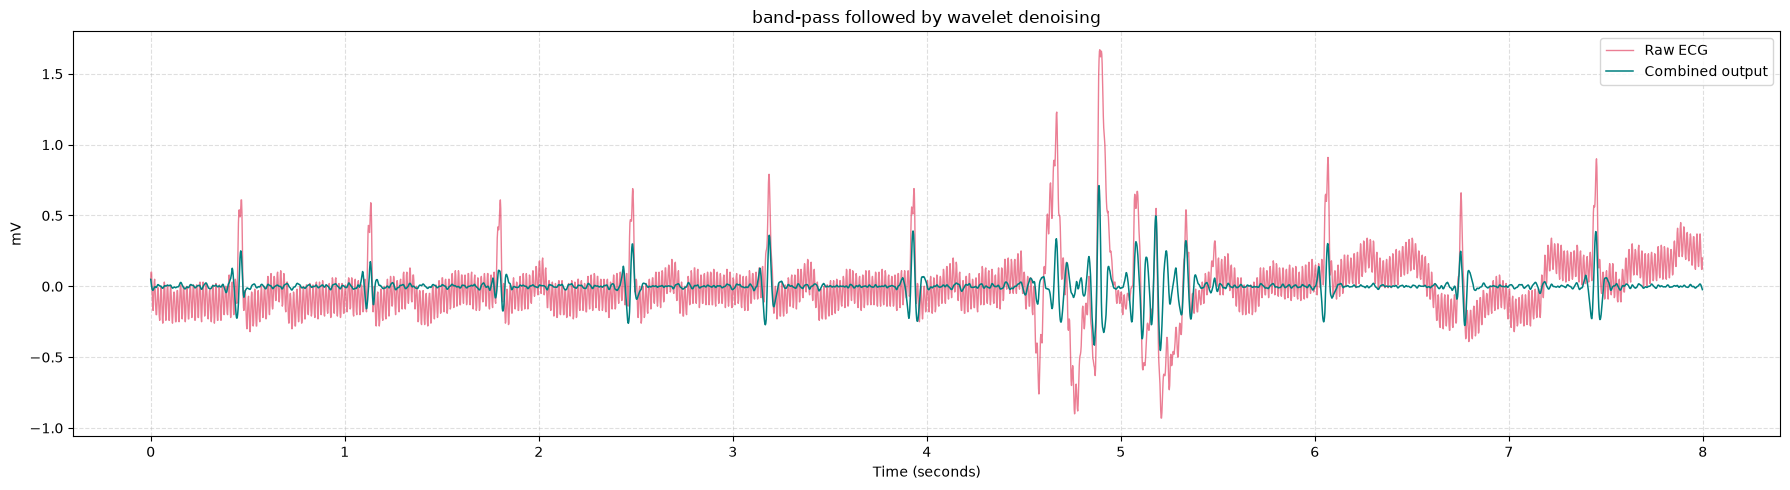

In [107]:
combined = wavelet_denoise(bandpass)
plt.figure(figsize=(25, 5))
plot_pair(raw, combined, "band-pass followed by wavelet denoising", "Combined output")


## All methods

The black curve is the raw signal. Compare each coloured method at the same time. Repeat the notebook for all four channels by changing `CHANNEL` at the top.


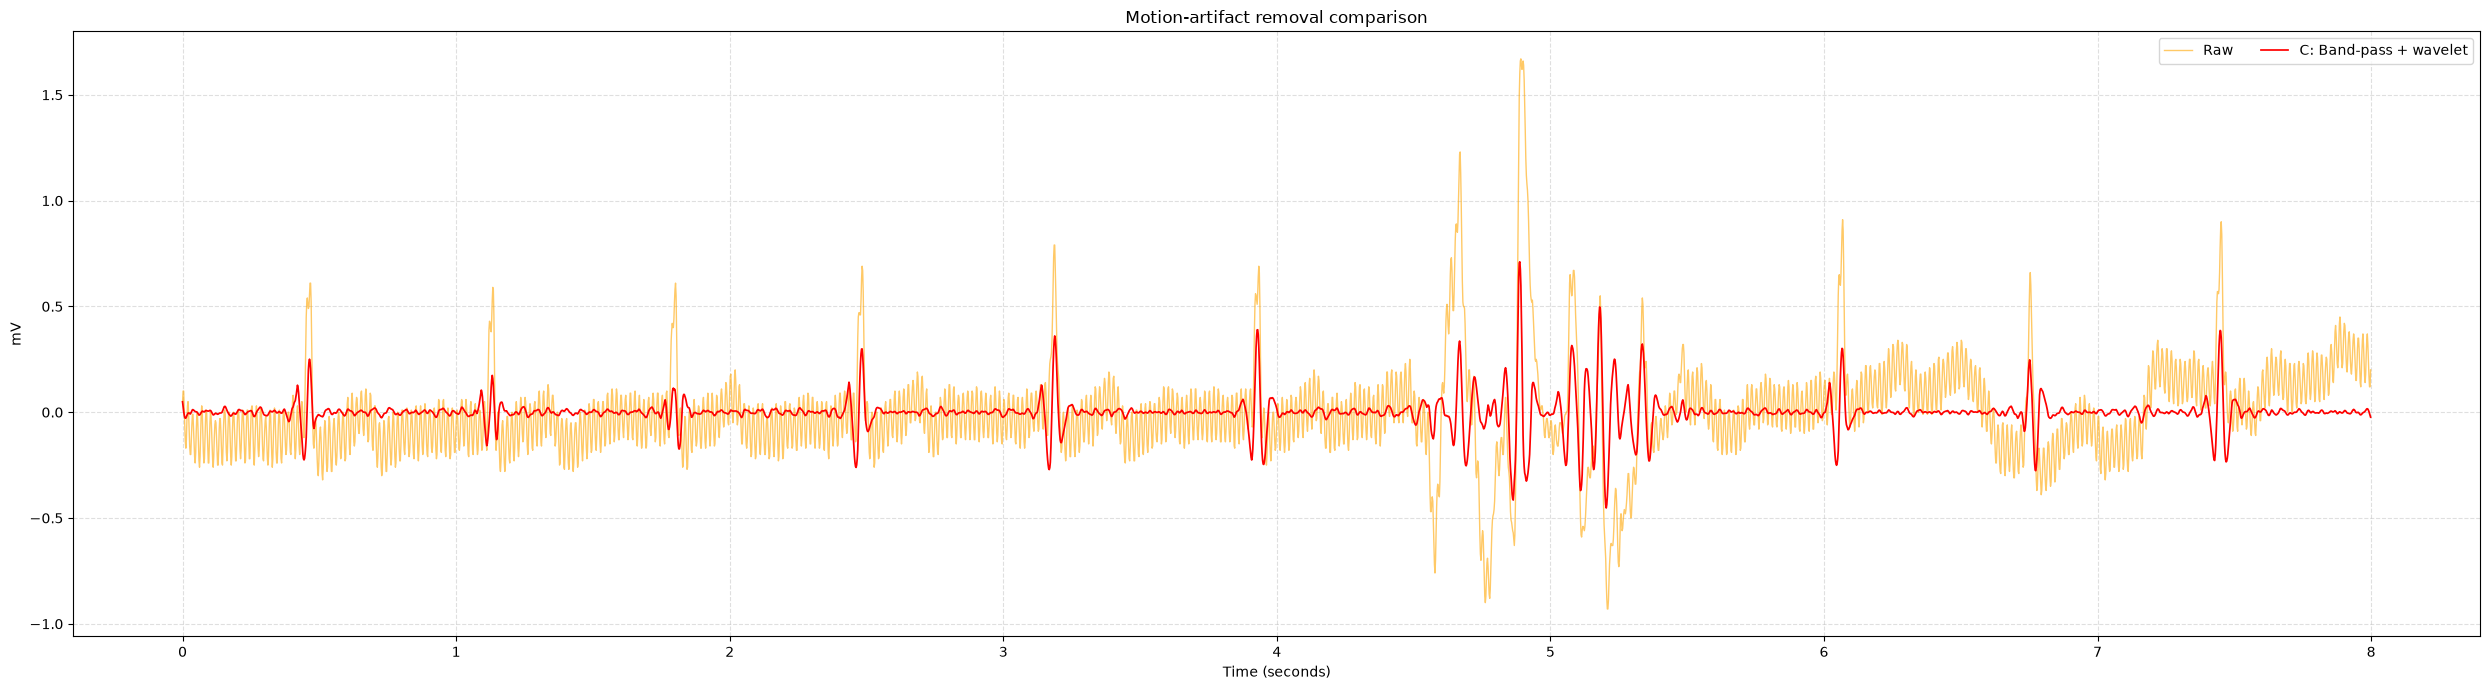

In [ ]:
n = min(len(raw), int(DISPLAY_SECONDS * fs))
t = np.arange(n) / fs
plt.figure(figsize=(25, 7))
plt.plot(t, raw[:n], color="orange", alpha=.6, lw=1, label="Raw")
# plt.plot(t, bandpass[:n],color="blue", lw=1, label="A: Band-pass")
# plt.plot(t, wavelet[:n], color="green", lw=1, label="B: Wavelet")
plt.plot(t, combined[:n], color="red", lw=1.25, label="C: Band-pass + wavelet")
plt.plot(t,)

plt.title(f"Motion-artifact removal comparison")
plt.xlabel("Time (seconds)"); plt.ylabel(unit)
plt.grid(True, linestyle="--", alpha=.4); plt.legend(ncol=2)
plt.tight_layout(); plt.show()


In [13]:
BEST_METHOD = "combined"  # "bandpass", "wavelet", or "combined"
outputs = {"bandpass": bandpass, "wavelet": wavelet, "combined": combined}
if BEST_METHOD not in outputs:
    raise ValueError("BEST_METHOD must be 'bandpass', 'wavelet', or 'combined'")
out_file = DATA_FOLDER / f"{RECORD_ID}_{channel_name}_{BEST_METHOD}_cleaned.csv"
np.savetxt(out_file, np.c_[np.arange(len(raw))/fs, outputs[BEST_METHOD]], delimiter=",", header="time_seconds,cleaned_ecg", comments="")
print(f"Saved: {out_file}")


Saved: C:\Users\jhala\OneDrive\Desktop\Internship\Datasets\ECG_DATASETS\test26_45j_ECG 3_combined_cleaned.csv


# Advanced methods

The methods below are more experimental. They are useful for comparison, but inspect their plots carefully because overly strong denoising can alter the real ECG. MACECGDB provides four ECG channels but no accelerometer or other dedicated noise-reference channel; therefore a true adaptive LMS/RLS noise canceller is not appropriate for this dataset.


## Stationary wavelet transform (SWT)

The earlier wavelet method downsamples at each level. SWT does not downsample, so it is shift-invariant: moving a heartbeat slightly in time does not change the result as much. We apply it after band-pass filtering and threshold only the detail coefficients.


<Figure size 2500x500 with 0 Axes>

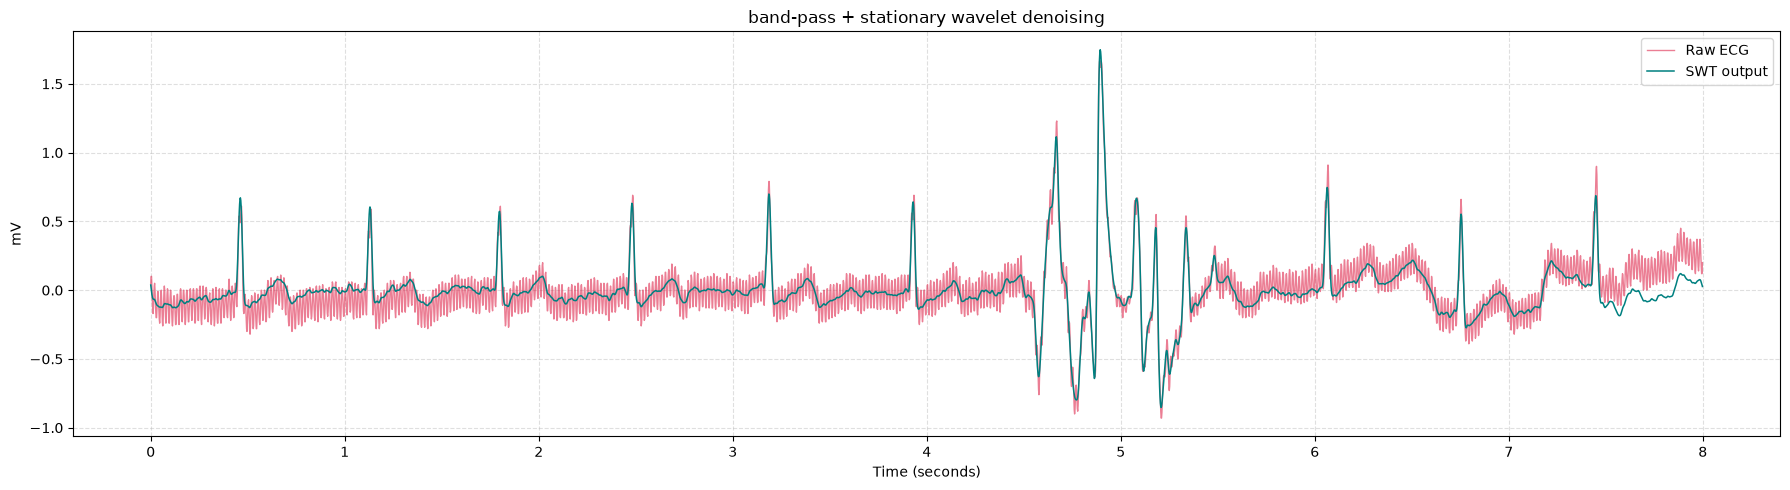

In [119]:
def swt_denoise(x, wavelet="sym4", level=4):
    """Shift-invariant wavelet denoising; input should already be baseline corrected."""
    level = min(level, pywt.swt_max_level(len(x)))
    if level < 1:
        return x.copy()
    block = 2 ** level
    padding = (-len(x)) % block
    padded = np.pad(x, (0, padding), mode="reflect") if padding else x.copy()
    coeffs = pywt.swt(padded, wavelet, level=level)
    sigma = np.median(np.abs(coeffs[-1][1])) / .6745
    threshold = sigma * np.sqrt(2 * np.log(len(padded)))
    filtered = [(approx, pywt.threshold(detail, threshold, mode="soft")) for approx, detail in coeffs]
    return pywt.iswt(filtered, wavelet)[:len(x)]

swt_output = swt_denoise(bandpass)
plt.figure(figsize=(25, 5))
plot_pair(raw, swt_output, "band-pass + stationary wavelet denoising", "SWT output")


## Singular Spectrum Analysis (SSA)

SSA turns the time series into an overlapping-window matrix, uses singular-value decomposition to keep its strongest repeating patterns, and reconstructs the signal. ECG morphology is repetitive, while sudden motion artifact is less consistent. `rank` controls the number of patterns retained: use 8 first; try 6 or 10 only if needed.


<Figure size 2500x500 with 0 Axes>

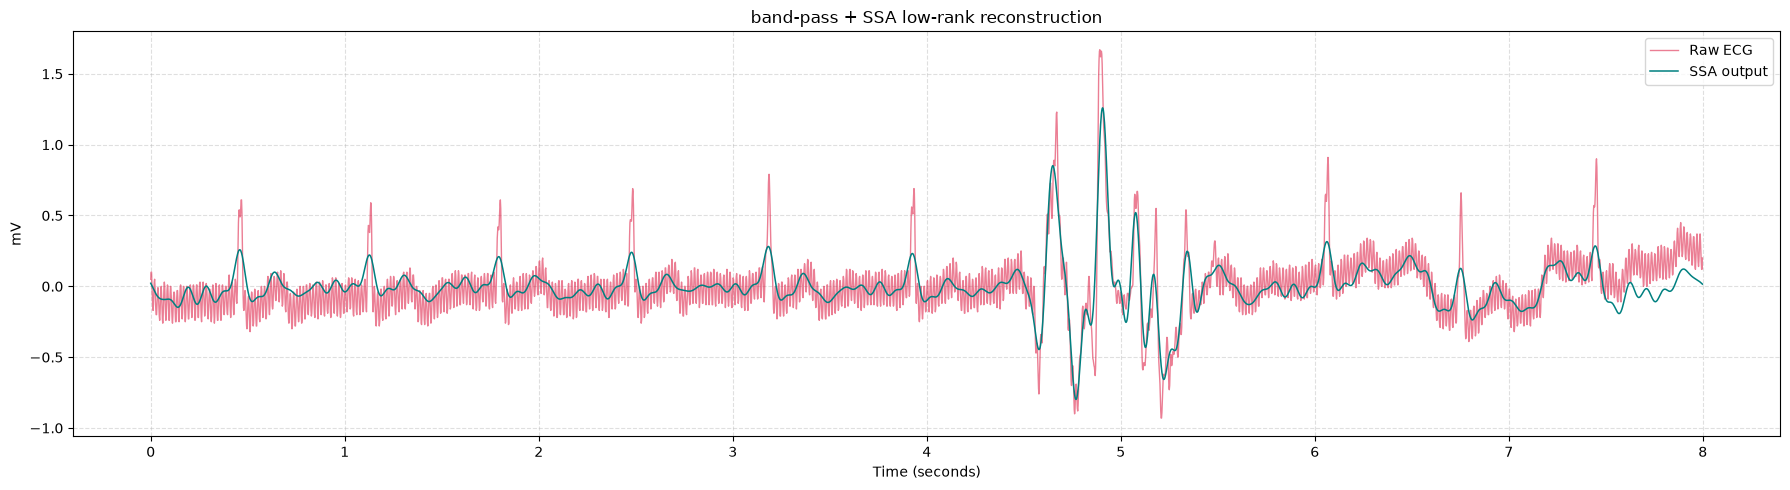

In [120]:
def ssa_denoise(x, window_length=200, rank=8):
    """Low-rank SSA reconstruction. Use after band-pass filtering, not on a very short signal."""
    n = len(x)
    L = min(window_length, n // 3)
    if L < 4:
        return x.copy()
    K = n - L + 1
    trajectory = np.lib.stride_tricks.sliding_window_view(x, L).T
    u, singular_values, vt = np.linalg.svd(trajectory, full_matrices=False)
    r = min(rank, len(singular_values))
    reconstructed = (u[:, :r] * singular_values[:r]) @ vt[:r, :]
    # Diagonal averaging (Hankelisation) returns from the matrix to a 1-D ECG signal.
    result = np.zeros(n)
    counts = np.zeros(n)
    for column in range(K):
        result[column:column + L] += reconstructed[:, column]
        counts[column:column + L] += 1
    return result / counts

ssa_output = ssa_denoise(bandpass, window_length=200, rank=8)
plt.figure(figsize=(25, 5))
plot_pair(raw, ssa_output, "band-pass + SSA low-rank reconstruction", "SSA output")


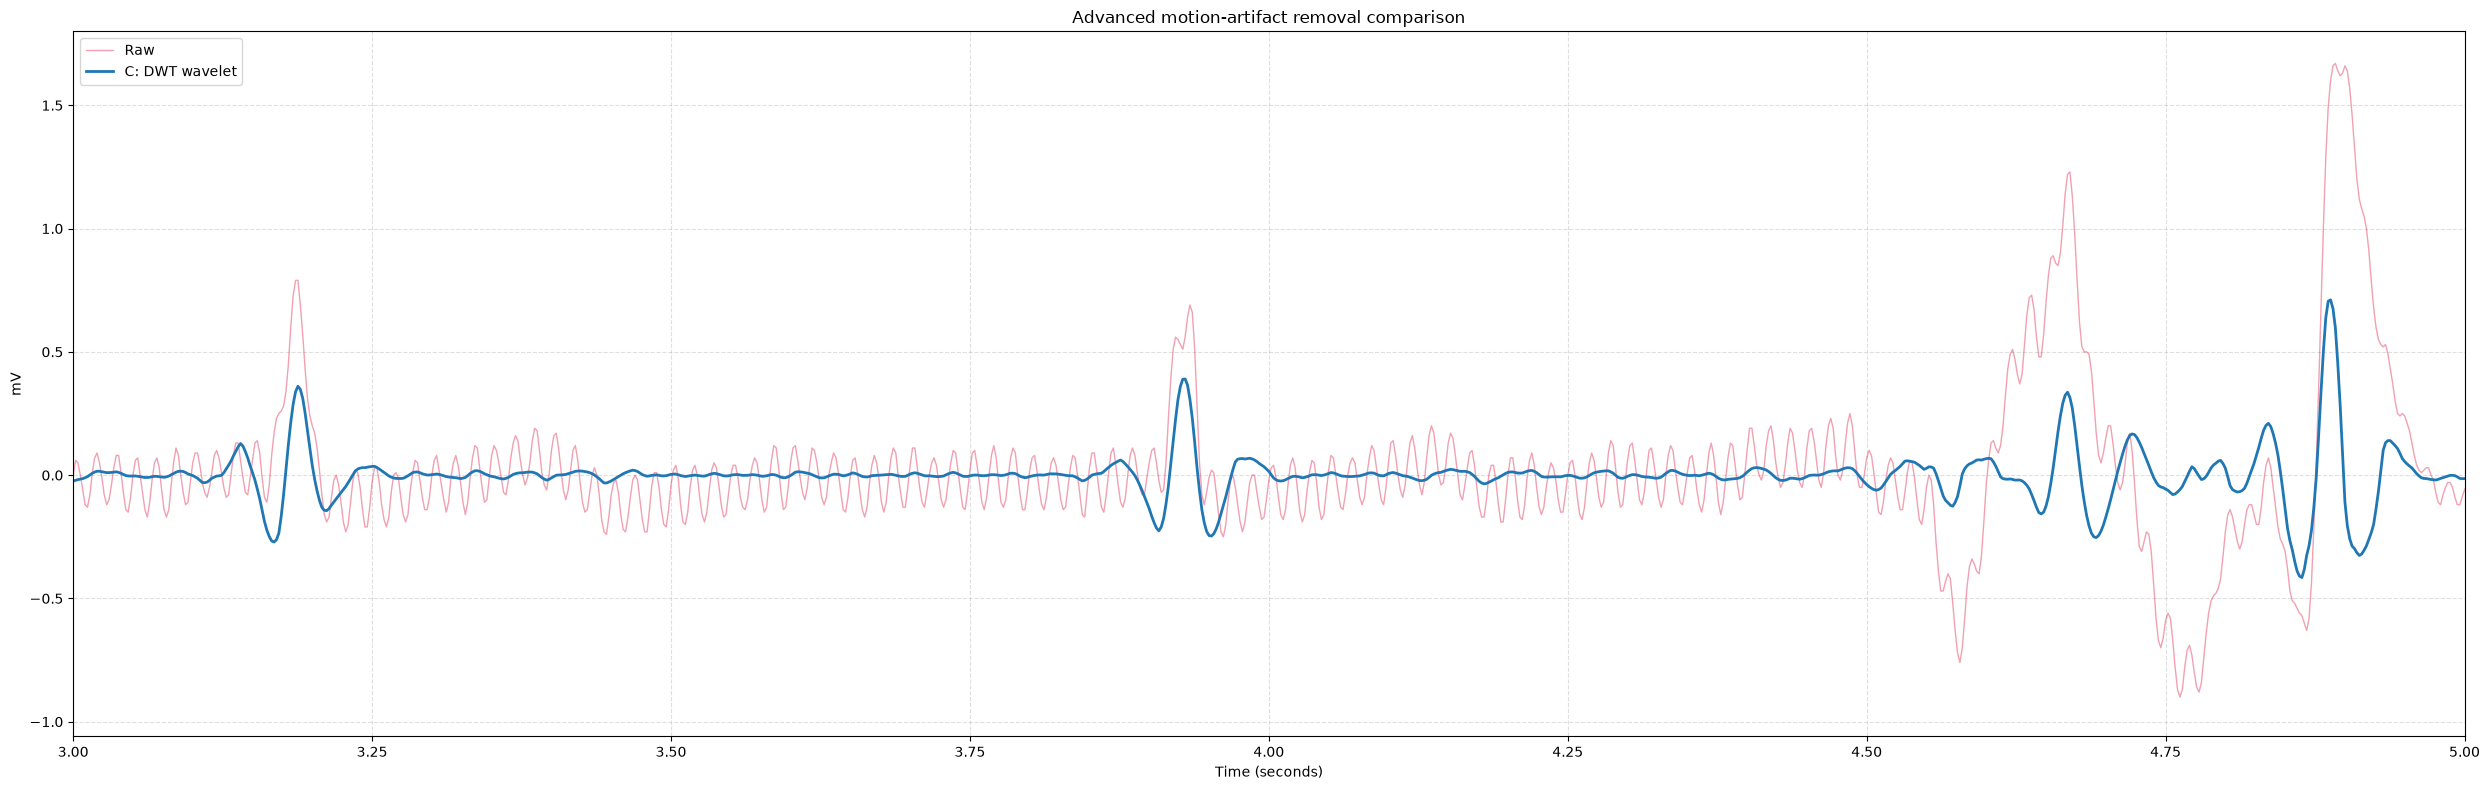

In [133]:
n = min(len(raw), int(DISPLAY_SECONDS * fs))
t = np.arange(n) / fs
plt.figure(figsize=(25, 8))
plt.plot(t, raw[:n], color="crimson", alpha=0.4, lw=1, label="Raw")
plt.plot(t, combined[:n], lw=2,alpha=1.0, label="C: DWT wavelet")
# plt.plot(t, swt_output[:n], lw=2, alpha=1.0, label="D: SWT wavelet")
# plt.plot(t, ssa_output[:n], lw=1.3, label="E: SSA")
plt.title(f"Advanced motion-artifact removal comparison")
plt.xlabel("Time (seconds)"); plt.ylabel(unit)
plt.xlim(3, 5)
plt.grid(True, linestyle="--", alpha=.4); plt.legend()
plt.tight_layout(); plt.show()


In [18]:
# Optional: save an advanced result after choosing it from the final comparison.
ADVANCED_BEST_METHOD = "ssa"  # choose: "combined", "swt", or "ssa"
advanced_outputs = {"combined": combined, "swt": swt_output, "ssa": ssa_output}
if ADVANCED_BEST_METHOD not in advanced_outputs:
    raise ValueError("ADVANCED_BEST_METHOD must be 'combined', 'swt', or 'ssa'")
advanced_file = DATA_FOLDER / f"{RECORD_ID}_{channel_name}_{ADVANCED_BEST_METHOD}_cleaned.csv"
np.savetxt(advanced_file, np.c_[np.arange(len(raw))/fs, advanced_outputs[ADVANCED_BEST_METHOD]], delimiter=",", header="time_seconds,cleaned_ecg", comments="")
print(f"Saved: {advanced_file}")


Saved: C:\Users\jhala\OneDrive\Desktop\Internship\Datasets\ECG_DATASETS\test26_45j_ECG 3_ssa_cleaned.csv
